In [2]:
# dependencies

import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt

In [3]:
df = pd.read_csv('l-37-house.csv', usecols=['GarageQual','FireplaceQu','SalePrice'])

df.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [4]:
# regression problem -- traget ==> numerical col , predict price

df.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

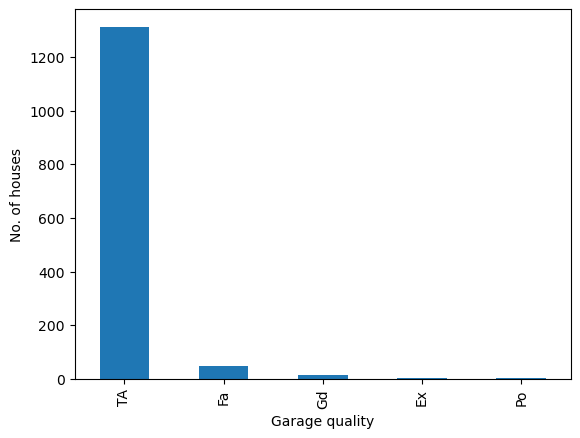

In [5]:
df['GarageQual'].value_counts().plot(kind='bar')
plt.xlabel('Garage quality')
plt.ylabel('No. of houses')
plt.show()

In [6]:
df['GarageQual'].mode()

0    TA
Name: GarageQual, dtype: object

In [7]:
import seaborn as sns

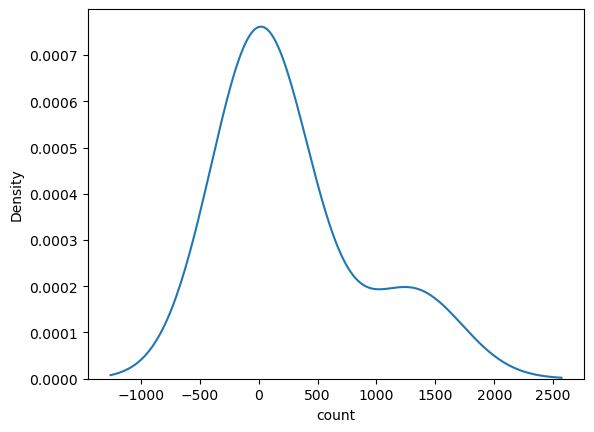

In [9]:
sns.kdeplot(data=df, x=df['GarageQual'].value_counts())

plt.show()

In [10]:
df[df['GarageQual']=='TA']

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000
...,...,...,...
1455,TA,TA,175000
1456,TA,TA,210000
1457,Gd,TA,266500
1458,NaN,TA,142125


In [12]:
df[df['GarageQual']=='TA']['SalePrice']

0       208500
1       181500
2       223500
3       140000
4       250000
         ...  
1455    175000
1456    210000
1457    266500
1458    142125
1459    147500
Name: SalePrice, Length: 1311, dtype: int64

Text(0.5, 1.0, 'GarageQual')

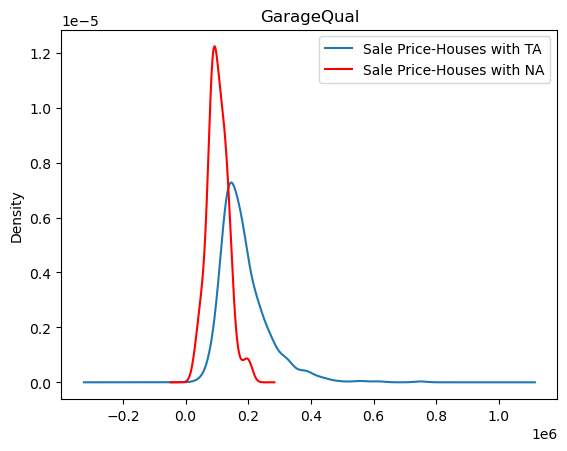

In [25]:
fig = plt.figure()
ax = fig.add_subplot(111)



df[df['GarageQual']=='TA']['SalePrice'].plot(kind='kde',ax=ax)

df[df['GarageQual'].isnull()]['SalePrice'].plot(kind='kde', color = 'red',ax=ax)

lines, labels= ax.get_legend_handles_labels()

lables=('Sale Price-Houses with TA','Sale Price-Houses with NA')

ax.legend(lines, lables, loc='best')
plt.title('GarageQual')


Now lets replace NA with == TA (this is the mode values of this col) 

In [26]:
temp = df[df['GarageQual']=='TA']['SalePrice']

In [27]:
df['GarageQual'].fillna('TA', inplace=True)

/var/folders/jd/5681g6rx58xgpr8txbqb17p80000gn/T/ipykernel_37562/1818999247.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['GarageQual'].fillna('TA', inplace=True)


In [28]:
df['GarageQual'].value_counts()

GarageQual
TA    1392
Fa      48
Gd      14
Ex       3
Po       3
Name: count, dtype: int64

In [29]:
df.isnull().mean()*100

FireplaceQu    47.260274
GarageQual      0.000000
SalePrice       0.000000
dtype: float64

Now we have sucessfully imputed garagequality with mode values

<Axes: xlabel='GarageQual'>

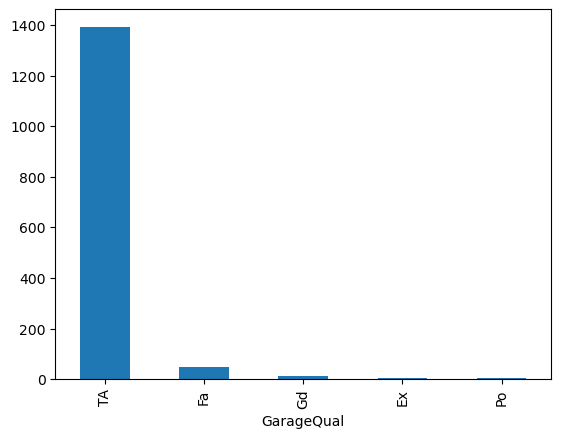

In [31]:
df['GarageQual'].value_counts().plot(kind='bar')

Text(0.5, 1.0, 'GarageQual')

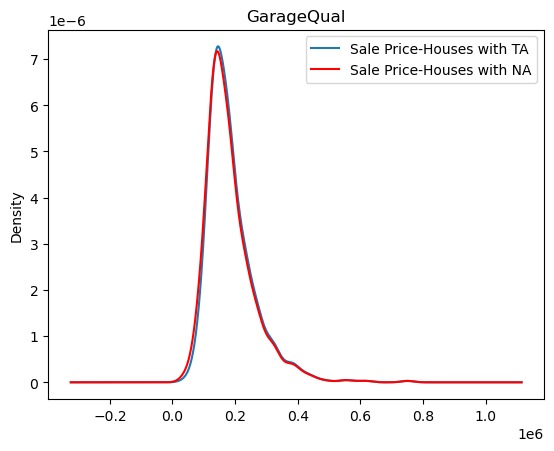

In [33]:
fig = plt.figure()
ax = fig.add_subplot(111)


# original graph 
temp.plot(kind='kde', ax=ax)




# distrubution of varibales after imputation
df[df['GarageQual']== 'TA']['SalePrice'].plot(kind='kde', color = 'red',ax=ax)

lines, labels= ax.get_legend_handles_labels()

lables=('Sale Price-Houses with TA','Sale Price-Houses with NA')

ax.legend(lines, lables, loc='best')
plt.title('GarageQual')

### now we will do the same for other col with almost 50% missing val

In [34]:
df['FireplaceQu'].value_counts()

FireplaceQu
Gd    380
TA    313
Fa     33
Ex     24
Po     20
Name: count, dtype: int64

In [37]:
df['FireplaceQu'].isnull().mean()

0.4726027397260274

<Axes: xlabel='FireplaceQu'>

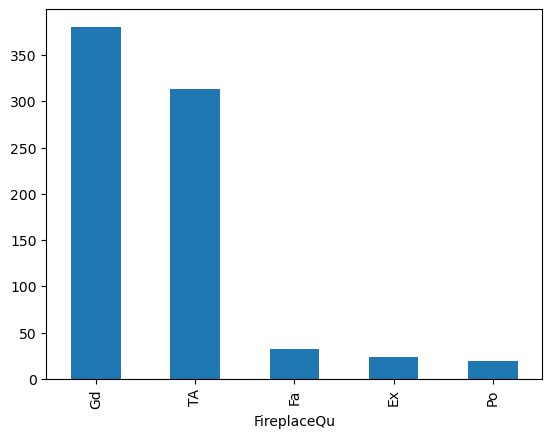

In [38]:
df['FireplaceQu'].value_counts().plot(kind='bar')


## whenever we replace with mode == we want that one category is domianant , but there 2 category are domiant --> another sign of redflag

In [39]:
df['FireplaceQu'].mode()


0    Gd
Name: FireplaceQu, dtype: object

Text(0.5, 1.0, 'FireplaceQu')

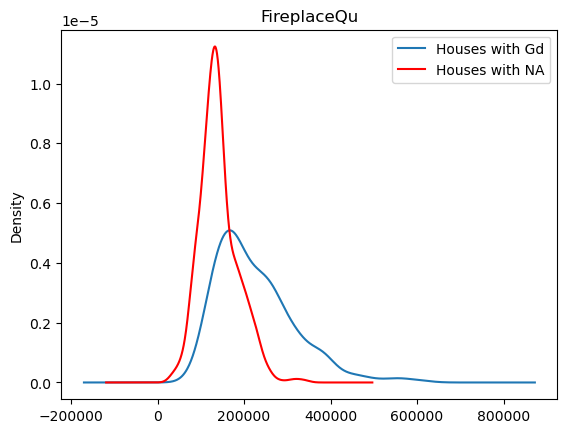

In [40]:
fig = plt.figure()
ax = fig.add_subplot(111)

df[df['FireplaceQu']=='Gd']['SalePrice'].plot(kind='kde', ax=ax)

df[df['FireplaceQu'].isnull()]['SalePrice'].plot(kind='kde', ax=ax, color='red')

lines, labels = ax.get_legend_handles_labels()
labels = ['Houses with Gd', 'Houses with NA']
ax.legend(lines, labels, loc='best')

plt.title('FireplaceQu')

In [41]:
# now lets store the original graph and also impute

In [42]:
temp = df[df['FireplaceQu']=='Gd']['SalePrice']


In [43]:
df['FireplaceQu'].fillna('Gd', inplace=True)

<Axes: xlabel='FireplaceQu'>

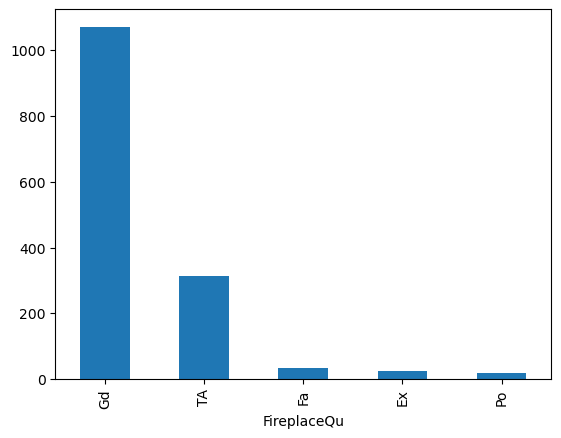

In [44]:
df['FireplaceQu'].value_counts().plot(kind='bar')

as we can see that now 'gd'. category is dominating --> cause there were lots of missing values 

Text(0.5, 1.0, 'FireplaceQu')

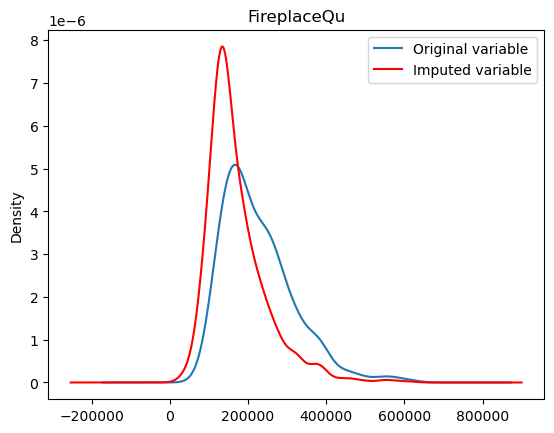

In [45]:
fig = plt.figure()
ax = fig.add_subplot(111)


temp.plot(kind='kde', ax=ax)

# distribution of the variable after imputation
df[df['FireplaceQu'] == 'Gd']['SalePrice'].plot(kind='kde', ax=ax, color='red')

lines, labels = ax.get_legend_handles_labels()
labels = ['Original variable', 'Imputed variable']
ax.legend(lines, labels, loc='best')

# add title
plt.title('FireplaceQu')

even after imputing both graphs are not overlapping == sign of that its is not a good move here

# now we will do same thing using simple imputer class--> sklearn

In [46]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(df.drop(columns=['SalePrice']),df['SalePrice'],test_size=0.2)


from sklearn.impute import SimpleImputer


imputer = SimpleImputer(strategy='most_frequent')


X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_train)


imputer.statistics_




/opt/anaconda3/lib/python3.12/site-packages/sklearn/base.py:493: UserWarning: X does not have valid feature names, but SimpleImputer was fitted with feature names
  warnings.warn(


array(['Gd', 'TA'], dtype=object)

so here we are getting the mode of each col respectively